In [6]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy

In [7]:
df = pd.read_csv("../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)

## Momentum Strategy Results

In [8]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, 252, 0.001)

In [9]:
time_invested = momentum_results["time_invested"]

## Exposure Matched Random Strategies

In [10]:
def generate_random_signal_v2(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback, p = [1 - time_invested,time_invested])

    random_signal = random_signal + choice.tolist()

    return random_signal

In [11]:
df["Random Signal"] = generate_random_signal_v2(prices, 252)
random_signal = df["Random Signal"]

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return           -0.332673
cagr                   -0.015654
annual_volatility       0.168053
annual_sharpe          -0.009816
max_drawdown           -0.678474
calmar                 -0.023073
time_invested           0.768731
trades               2311.000000
dtype: float64

In [12]:
def run_simulation_v2(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v2(prices, 252)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [19]:
np.random.seed(44)

simulation_output = run_simulation_v2(10000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.575245,-0.032850,0.165722,-0.118693,-0.704884,-0.046603,0.775387,2261
1,-0.597904,-0.034916,0.170442,-0.123208,-0.682150,-0.051185,0.778483,2250
2,-0.535162,-0.029442,0.164602,-0.099071,-0.752120,-0.039145,0.771672,2311
3,-0.361064,-0.017322,0.165845,-0.022277,-0.705379,-0.024558,0.772755,2289
4,-0.314679,-0.014632,0.167466,-0.004329,-0.701865,-0.020848,0.769350,2326
...,...,...,...,...,...,...,...,...
9995,-0.783195,-0.057892,0.166565,-0.274553,-0.828475,-0.069878,0.777090,2241
9996,-0.507130,-0.027222,0.167211,-0.081445,-0.685674,-0.039701,0.773839,2267
9997,-0.230026,-0.010145,0.170311,0.025192,-0.723771,-0.014017,0.770898,2326
9998,-0.212672,-0.009284,0.172370,0.032085,-0.619701,-0.014982,0.780805,2164


In [20]:
print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

Sharpe Average: -0.0351
Sharpe Median:  -0.0355
Largest Sharpe: 0.2881
Average No. of Trades: 2252.3571
Average Time Invested: 0.7752


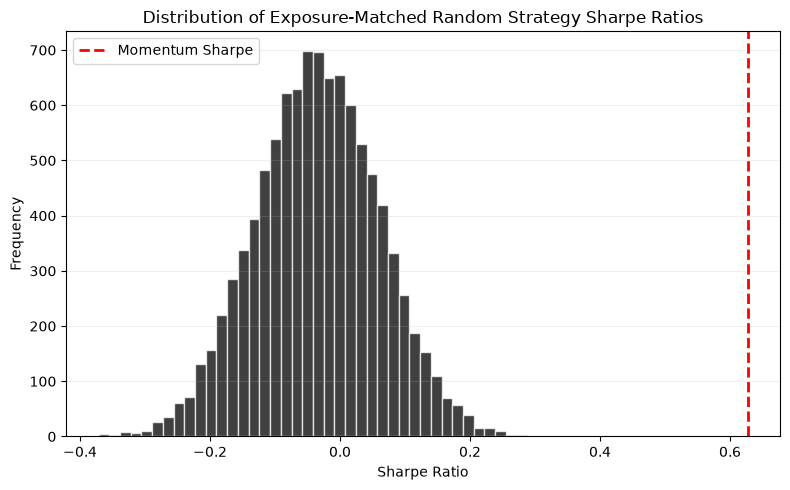

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(
    simulation_df["annual_sharpe"],
    bins=40,
    color="black",
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    momentum_results["annual_sharpe"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Momentum Sharpe"
)

plt.xlabel("Sharpe Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Exposure-Matched Random Strategy Sharpe Ratios")

plt.legend()

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()